# Vehicle Speed Estimation with Optical Flow and Linear Regression
**Course Track:** Stanford CS229 Machine Learning — Term Project  
**Category:** Computer Vision (Application & Feature-Engineering Project)

---
## 1. Mathematical Formulation & Pinhole Ground-Plane Kinematics
Given consecutive monocular dashcam frames $(I_{t-1}, I_t) \in \mathbb{R}^{H \times W \times 3}$ sampled at $20\text{ Hz}$ ($\Delta t = 0.05\text{ s}$), we seek to estimate instantaneous ego-vehicle longitudinal speed $\hat{v}_t \in \mathbb{R}_{\ge 0}$ ($\text{m/s}$). Under a pinhole camera at height $H_c$ with focal length $f$ and horizon row $y_0$, a static planar road point at depth $Z = f H_c / (y - y_0)$ induces image-plane optical flow:
$$\dot{y}(x, y, t) = \frac{(y - y_0)^2}{f H_c} v_t + f \omega_{\text{pitch}}(t), \qquad \dot{x}(x, y, t) = \frac{(x - x_0)(y - y_0)}{f H_c} v_t$$
This notebook executes the end-to-end pipeline: data loading/synthesis, contiguous temporal splitting, CLAHE + trapezoidal ROI preprocessing, Dense Farnebäck and Sparse Lucas-Kanade optical flow extraction, $3 \times 3$ multi-zone perspective feature engineering, regularized regression ($\ell_2$ Ridge, $\ell_1$ Lasso, OLS, RBF-SVR, Random Forest), 1D Kinematic Kalman Filtering, 9-stage ablation, and stratified error analysis.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT_DIR = (
    os.path.abspath(os.path.join(os.getcwd(), ".."))
    if os.path.basename(os.getcwd()) == "notebooks"
    else os.path.abspath(os.getcwd())
)
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

from src.data_loader import load_config, load_or_generate_dataset, contiguous_temporal_split
from src.eda import compute_eda_summary
from src.feature_engineering import extract_dataset_features
from src.models import train_all_models, extract_linear_coefficients
from src.evaluate import (
    evaluate_all_models,
    run_ablation_study,
    run_error_analysis_slices,
    evaluate_leakage_experiment,
)
from src.visualize import (
    plot_fig1_roi_and_optical_flow,
    plot_fig2_eda_and_correlations,
    plot_fig3_model_comparison_and_trajectories,
    plot_fig4_ablation_and_regularization,
    plot_fig5_error_analysis_and_residuals,
)

cfg = load_config(os.path.join(ROOT_DIR, "configs", "config.yaml"))
print("Loaded configuration successfully. Seed:", cfg["project"]["seed"], "FPS:", cfg["project"]["fps"])

Loaded configuration successfully. Seed: 42 FPS: 20.0


## 2. Dataset Loading, Feature Extraction & Contiguous Chronological Splitting
We enforce a strict **contiguous chronological split** ($70\%$ Train, $15\%$ Validation, $15\%$ Test) with a $5$-frame ($0.25\text{ s}$) embargo buffer to prevent temporal autocorrelation leakage between adjacent $50\text{ ms}$ video frames.

In [2]:
dataset = load_or_generate_dataset(cfg, ROOT_DIR)
features_df = extract_dataset_features(dataset.frames, cfg)
splits = contiguous_temporal_split(
    features_df,
    dataset.speeds,
    dataset.timestamps,
    train_ratio=float(cfg["data"]["train_ratio"]),
    val_ratio=float(cfg["data"]["val_ratio"]),
)
eda_tables = compute_eda_summary(dataset, features_df, splits)
print(f"Extracted feature matrix shape: {features_df.shape}")
display(eda_tables["split_summary"])
display(eda_tables["feature_correlations"].head(10))

Extracted feature matrix shape: (1200, 166)


   split  num_frames  duration_sec  mean_speed_ms  std_speed_ms  min_speed_ms  median_speed_ms  iqr_speed_ms  max_speed_ms  mean_abs_accel_ms2
0  train         835         41.75      14.636933      7.287153      1.200000        13.606351     11.374947     28.627423            2.700768
1    val         175          8.75      18.777317      7.579230      1.927369        23.076011     10.818612     25.311677            2.974648
2   test         180          9.00      13.006665      8.287776      1.262083        12.371767     15.021626     26.265437            2.801335


                       feature  pearson_r  abs_pearson_r  spearman_r
0  zone_near_center_median_mag   0.911791       0.911791    0.916400
1   zone_near_right_median_mag   0.910133       0.910133    0.913813
2     zone_near_right_mean_mag   0.899989       0.899989    0.909243
3       zone_near_right_abs_vx   0.897793       0.897793    0.904608
4    zone_near_center_mean_mag   0.894574       0.894574    0.904338
5    zone_near_left_median_mag   0.889761       0.889761    0.895699
6      zone_near_left_mean_mag   0.889379       0.889379    0.898597
7        zone_near_left_abs_vx   0.888449       0.888449    0.894962
8      zone_near_right_p75_mag   0.877171       0.877171    0.877725
9       zone_near_left_p75_mag   0.871868       0.871868    0.874597


## 3. Preprocessing, Dual Optical Flow & Exploratory Data Analysis Figures

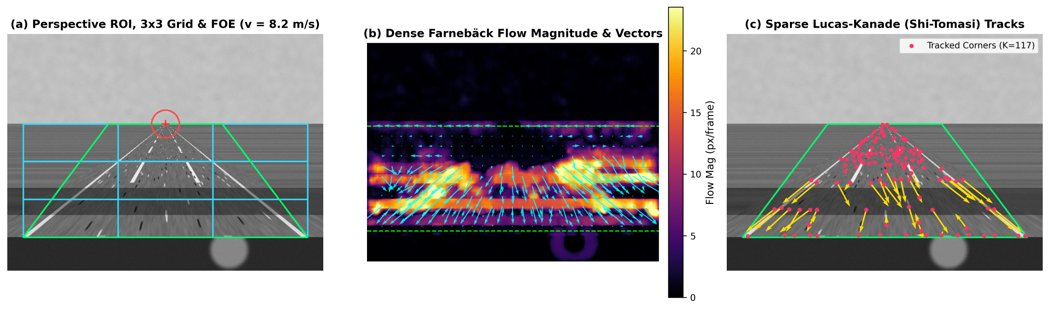

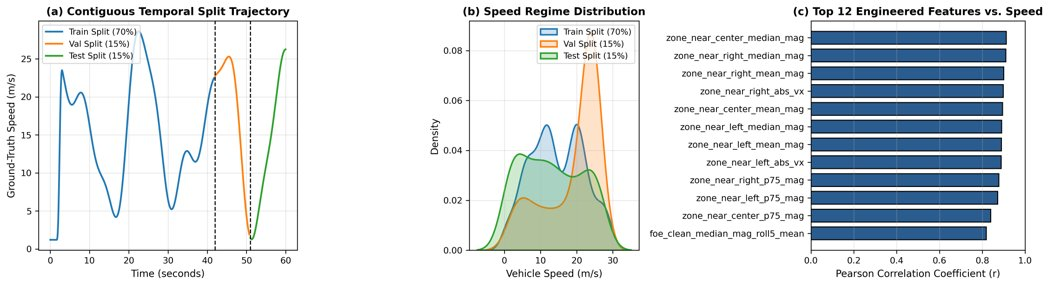

In [3]:
fig_dir = os.path.join(ROOT_DIR, "figures")
f1 = plot_fig1_roi_and_optical_flow(dataset, cfg, fig_dir)
f2 = plot_fig2_eda_and_correlations(dataset, splits, eda_tables, fig_dir)
display(Image(filename=f1))
display(Image(filename=f2))

## 4. Model Training, Regularization & 1D Kinematic Kalman Filtering
We compare Univariate OLS, Multivariate OLS, $\ell_2$ Ridge Regression, $\ell_1$ Lasso Regression, non-linear RBF-SVR, and Random Forest across Raw, Causal Moving Average, Causal EMA, and 1D Constant-Acceleration Kalman Filtering.

           model_key                         model_name     post_filter  num_features  best_hyperparam  train_MSE    val_MSE   test_MSE  test_RMSE  test_MAE   test_R2   test_P95
0     Univariate_OLS  Univariate OLS (Global Mean Flow)             Raw             1            0.000  28.153199  37.399596  50.384889   7.098231  5.460155  0.266459  13.748540
1     Univariate_OLS  Univariate OLS (Global Mean Flow)  Moving_Average             1            0.000  28.153199  37.399596  48.026542   6.930118  5.300720  0.300794  13.743625
3     Univariate_OLS  Univariate OLS (Global Mean Flow)   Kalman_Filter             1            0.000  28.153199  37.399596  45.269359   6.728251  5.315105  0.340935  12.801852
4   Multivariate_OLS                   Multivariate OLS             Raw           166            0.000   0.144993   0.772638   0.582611   0.763290  0.456934  0.991518   1.143948
5   Multivariate_OLS                   Multivariate OLS  Moving_Average           166            0.000   0.144

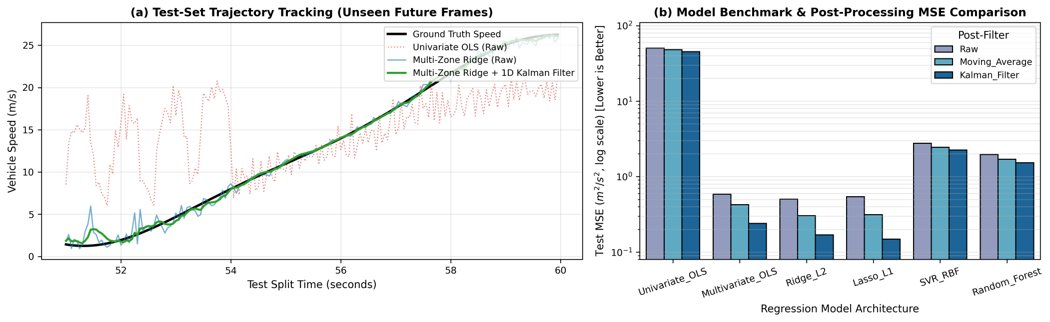

In [4]:
X_train, y_train, _, _ = splits["train"]
X_val, y_val, _, _ = splits["val"]
artifacts = train_all_models(X_train, y_train, X_val, y_val, cfg)
eval_df, test_preds = evaluate_all_models(artifacts, splits, cfg)
display(eval_df[eval_df["post_filter"].isin(["Raw", "Moving_Average", "Kalman_Filter"])])

f3 = plot_fig3_model_comparison_and_trajectories(splits, eval_df, test_preds, fig_dir)
display(Image(filename=f3))

## 5. Systematic 9-Stage Ablation Study & Linear Weight Interpretability

                               Stage  Num_Features  Condition_Number  OLS_Test_MSE  Ridge_Val_MSE  Ridge_Test_MSE  Ridge_Test_RMSE  Ridge_Test_MAE  Ridge_Test_R2
0           1_FullFrame_Global_Dense             8      1.098766e+05     12.691746       6.571350       12.515251         3.537690        2.537543       0.817794
1         2_ROI_Cropped_Global_Dense             8      9.962112e+03      9.356702       5.014198        9.533291         3.087603        2.231007       0.861207
2           3_ROI_Sparse_LucasKanade             9      1.674143e+03      8.164192       7.159237        8.158642         2.856334        2.225818       0.881220
3               4_ROI_FOE_Radial_IPM            11      1.270722e+04      2.299509       2.184909        2.380711         1.542955        1.142905       0.965340
4               5_MultiZone_3x3_Grid            85      2.657263e+28      1.233752       1.510685        1.446585         1.202740        0.663014       0.978940
5          6_Spatial_Hybrid_

                               feature  coefficient  abs_coefficient
0              zone_mid_center_mean_vy     5.695911         5.695911
1              zone_mid_center_mean_vr    -4.247128         4.247128
2                     foe_clean_abs_vx     3.813254         3.813254
3         zone_mid_center_mean_vr_lag1    -3.421967         3.421967
4                    foe_clean_mean_vy     2.980784         2.980784
5                   foe_clean_mean_mag    -2.929859         2.929859
6   zone_mid_center_mean_vr_roll3_mean    -2.648838         2.648838
7             zone_mid_center_mean_mag     2.519425         2.519425
8     foe_clean_ipm_vy_mean_roll5_mean     2.184556         2.184556
9              zone_mid_right_mean_mag    -2.047228         2.047228
10                   foe_clean_mean_vr    -1.946542         1.946542
11       zone_mid_center_mean_vr_diff1    -1.819077         1.819077


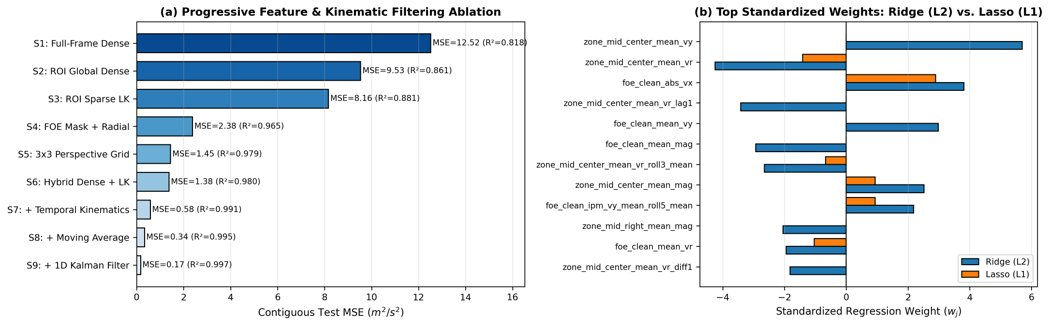

In [5]:
ablation_df = run_ablation_study(features_df, splits, cfg)
display(ablation_df)

ridge_coefs = extract_linear_coefficients(artifacts["Ridge_L2"])
display(ridge_coefs.head(12))

f4 = plot_fig4_ablation_and_regularization(ablation_df, artifacts["Ridge_L2"], artifacts["Lasso_L1"], fig_dir)
display(Image(filename=f4))

## 6. Stratified Error Analysis & Temporal Leakage Quantification

=== Error Slice: regime ===
=== Error Slice: lighting ===
=== Error Slice: pitch_condition ===
=== Error Slice: kinematic_state ===
=== Temporal Data Leakage Experiment ===


               regime  frames  mean_true_speed   raw_MSE    kf_MSE   raw_MAE    kf_MAE  mean_signed_bias  raw_RMSE   kf_RMSE  mse_reduction_pct
0  high_speed_highway      53        23.543060  0.271678  0.066999  0.437177  0.210734          0.019106  0.521227  0.258842          75.338840
1     low_speed_urban      61         3.686844  1.179768  0.422633  0.764740  0.496830          0.138044  1.086171  0.650102          64.176580
2     medium_arterial      66        13.159395  0.062428  0.014972  0.186000  0.098155         -0.003924  0.249857  0.122359          76.017623


          lighting  frames  mean_true_speed   raw_MSE    kf_MSE   raw_MAE    kf_MAE  mean_signed_bias  raw_RMSE   kf_RMSE  mse_reduction_pct
0  normal_daylight     119        17.784052  0.155624  0.038144  0.297869  0.148295          0.006333  0.394492  0.195304           75.48986
1  shadow_or_glare      61         3.686844  1.179768  0.422633  0.764740  0.496830          0.138044  1.086171  0.650102           64.17658


     pitch_condition  frames  mean_true_speed   raw_MSE    kf_MSE   raw_MAE    kf_MAE  mean_signed_bias  raw_RMSE   kf_RMSE  mse_reduction_pct
0  high_pitch_jitter      90        14.022368  0.636196  0.168098  0.484300  0.257042          0.053391  0.797619  0.409997          73.577713
1   low_pitch_jitter      90        11.990962  0.369193  0.168788  0.427873  0.275777          0.048546  0.607613  0.410838          54.281920


     kinematic_state  frames  mean_true_speed   raw_MSE    kf_MSE   raw_MAE    kf_MAE  mean_signed_bias  raw_RMSE   kf_RMSE  mse_reduction_pct
0  rapid_accel_decel     164        13.237521  0.321385  0.103404  0.403678  0.228734          0.002873  0.566908  0.321565          67.825531
1      steady_cruise      16        10.640391  2.361123  0.835093  0.993273  0.652583          0.543946  1.536595  0.913834          64.631540


                             Split_Protocol  Eval_MSE  Eval_RMSE   Eval_R2
0  Random 5-Fold Shuffle (Temporal Leakage)  0.404452   0.635966  0.993158
1  Contiguous Temporal Split (Leakage-Free)  0.502695   0.709010  0.992681


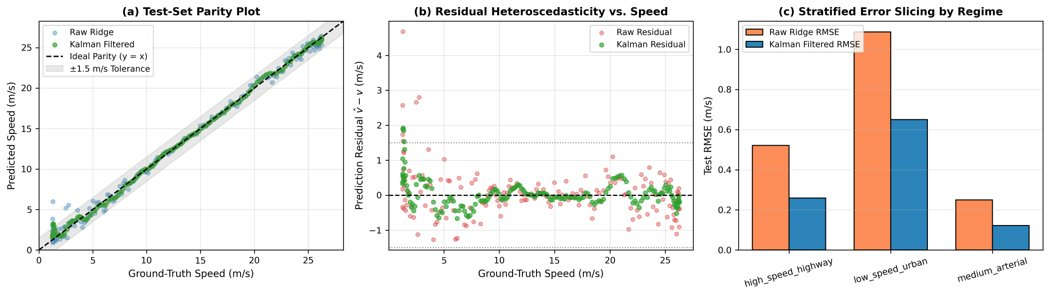

In [6]:
ridge_raw = test_preds["Ridge_L2"]["Raw"]
ridge_kf = test_preds["Ridge_L2"]["Kalman_Filter"]
error_slices = run_error_analysis_slices(dataset, splits, ridge_raw, ridge_kf)

for dim_name, slice_df in error_slices.items():
    print(f"=== Error Slice: {dim_name} ===")
    display(slice_df)

ridge_raw_row = eval_df[(eval_df["model_key"] == "Ridge_L2") & (eval_df["post_filter"] == "Raw")].iloc[0]
leak_df = evaluate_leakage_experiment(features_df, dataset.speeds, float(ridge_raw_row["test_MSE"]), float(ridge_raw_row["test_R2"]))
print("=== Temporal Data Leakage Experiment ===")
display(leak_df)

f5 = plot_fig5_error_analysis_and_residuals(splits, ridge_raw, ridge_kf, error_slices, fig_dir)
display(Image(filename=f5))